# Práctica clase 9 — Optimización clásica: el fondo del valle y la primera cerca

**BCD5105 · Modelado matemático · III Cuatrimestre 2026 · Lead University**

**Integrantes del grupo:** Daniel Vasquez Gonzalez · Santiago Villareal Arley · Maria José Gonzalez Quesada · Sharis Duarte Alvarado

> Tarea moral: no se entrega ni se califica. Las celdas de código llevan como comentario la salida esperada (verificada al ejecutar el notebook en orden).

Contenido:
1. A mano: un mínimo en dos variables y dos pasos de descenso
2. Descenso de gradiente propio contra BFGS
3. Despacho de un mes lluvioso y un escenario de El Niño
4. La decisión

In [1]:
# Celda de instalación: correrla apenas se abre el notebook (la usa la parte 3, opcional).
# scipy, numpy y matplotlib ya vienen en Colab.
!pip install -q --disable-pip-version-check cvxpy

---
## Parte 1: A mano

### Situación A: $f(x,y)=x^2+3y^2-2x+12y$

**1. Gradiente y punto crítico.**

$$\nabla f=\left(\frac{\partial f}{\partial x},\frac{\partial f}{\partial y}\right)=(2x-2,\;6y+12)$$

Igualando a cero: $2x-2=0\Rightarrow x=1$ y $6y+12=0\Rightarrow y=-2$. El único candidato es $(1,-2)$.

**2. Curvaturas y clasificación.**

$$\frac{\partial^2 f}{\partial x^2}=2>0,\qquad \frac{\partial^2 f}{\partial y^2}=6>0,\qquad \frac{\partial^2 f}{\partial x\,\partial y}=0$$

Las dos curvaturas son positivas (y el término cruzado es cero), así que es un **tazón** y $(1,-2)$ es un **mínimo**. Además $f$ es **convexa** (la matriz de segundas derivadas es $\mathrm{diag}(2,6)$, con ambos valores positivos en todo punto), por lo que ese mínimo es **global**: no hay otro valle donde quedar atrapado.

**3. Valor mínimo.**

$$f(1,-2)=1^2+3(-2)^2-2(1)+12(-2)=1+12-2-24=-13$$

Otra forma de verlo, completando cuadrados: $f(x,y)=(x-1)^2+3(y+2)^2-13$, que nunca baja de $-13$ y lo alcanza justo en $(1,-2)$.

### Situación B: descenso de gradiente en $g(x)=(x-1)^2$ desde $x_0=5$

**4. Regla.** Como $g'(x)=2(x-1)$:

$$x_{k+1}=x_k-\eta\,g'(x_k)=x_k-2\eta\,(x_k-1)$$

**5. Dos pasos con $\eta=0.25$.**

$$x_1=5-0.5\,(5-1)=3,\qquad x_2=3-0.5\,(3-1)=2$$

Se acercan al mínimo $x=1$: en cada paso la distancia a 1 se reduce a la mitad ($4\to2\to1\to\dots$).

**6. Contracción y divergencia.** Restando 1 a ambos lados de la regla:

$$x_{k+1}-1=(x_k-1)-2\eta(x_k-1)=(1-2\eta)(x_k-1)$$

Aplicando la relación $k$ veces: $x_k-1=(1-2\eta)^k\,(x_0-1)=4\,(1-2\eta)^k$. La distancia al mínimo se multiplica por $1-2\eta$ en cada paso, así que:

| Condición | Qué pasa |
|---|---|
| $\lvert1-2\eta\rvert<1$, es decir $0<\eta<1$ | Converge a 1 (más rápido cuanto más cerca de 0 esté el factor; con $\eta=0.5$ llega en un paso) |
| $\lvert1-2\eta\rvert=1$, es decir $\eta=1$ | Rebota entre 5 y $-3$ sin acercarse |
| $\lvert1-2\eta\rvert>1$, es decir $\eta>1$ | **Diverge**: el rebote crece en cada paso |

In [2]:
import numpy as np

# --- Situación A: comprobar el punto crítico, la clasificación y el valor mínimo
f = lambda x, y: x**2 + 3*y**2 - 2*x + 12*y
x_opt, y_opt = 1, -2                                   # sale de resolver ∇f = 0 a mano

print("∇f en (1, -2):", (2*x_opt - 2, 6*y_opt + 12))   # (0, 0): terreno plano
H = np.array([[2, 0], [0, 6]])                         # segundas derivadas (el cruzado es 0)
print("autovalores de H:", np.linalg.eigvalsh(H))      # [2. 6.]: ambos > 0 -> tazón
print("f(1, -2) =", f(x_opt, y_opt))                   # -13

# --- Situación B: g(x) = (x - 1)^2 con descenso de gradiente
def pasos(eta, x0=5.0, n=2):
    x = [x0]
    for _ in range(n):
        x.append(x[-1] - eta * 2 * (x[-1] - 1))        # g'(x) = 2(x - 1)
    return x

print("\neta = 0.25:", pasos(0.25))                     # [5.0, 3.0, 2.0]

for eta in [0.1, 0.5, 1.0, 1.1]:                       # factor de contracción |1 - 2*eta|
    camino = [round(v, 2) for v in pasos(eta, n=5)]
    print(f"eta = {eta:<4} factor = {abs(1 - 2*eta):.1f}  ->", camino)
# eta = 0.1  factor = 0.8  -> [5.0, 4.2, 3.56, 3.05, 2.64, 2.31]   (converge, lento)
# eta = 0.5  factor = 0.0  -> [5.0, 1.0, 1.0, 1.0, 1.0, 1.0]       (llega en un paso)
# eta = 1.0  factor = 1.0  -> [5.0, -3.0, 5.0, -3.0, 5.0, -3.0]    (rebota)
# eta = 1.1  factor = 1.2  -> [5.0, -3.8, 6.76, -5.91, 9.29, -8.95] (diverge)

∇f en (1, -2): (0, 0)
autovalores de H: [2. 6.]
f(1, -2) = -13

eta = 0.25: [5.0, 3.0, 2.0]
eta = 0.1  factor = 0.8  -> [5.0, 4.2, 3.56, 3.05, 2.64, 2.31]
eta = 0.5  factor = 0.0  -> [5.0, 1.0, 1.0, 1.0, 1.0, 1.0]
eta = 1.0  factor = 1.0  -> [5.0, -3.0, 5.0, -3.0, 5.0, -3.0]
eta = 1.1  factor = 1.2  -> [5.0, -3.8, 6.76, -5.91, 9.29, -8.95]


---
## Parte 2: Descenso de gradiente propio contra BFGS

Se programa el descenso de gradiente para la función de la situación A y se compara con `minimize` (método BFGS). Todas las corridas arrancan en $(4,1)$.

### 2.1 Descenso de gradiente con distintos tamaños de paso

In [3]:
import numpy as np
from scipy.optimize import minimize

def f(v):                                   # función objetivo de la situación A
    x, y = v
    return x**2 + 3*y**2 - 2*x + 12*y

def grad(v):                                # su gradiente, calculado a mano en la parte 1
    x, y = v
    return np.array([2*x - 2, 6*y + 12])

def descenso(eta, x0=(4.0, 1.0), tol=1e-6, max_iter=500):
    p = np.array(x0, dtype=float); camino = [p.copy()]
    for k in range(max_iter):
        g = grad(p)
        if np.linalg.norm(g) < tol: break           # terreno plano: paramos
        p = p - eta * g; camino.append(p.copy())    # paso cuesta abajo: x_{k+1} = x_k - eta * ∇f(x_k)
        if np.linalg.norm(p) > 1e6: break           # se disparó: lo damos por divergente
    return p, len(camino) - 1, np.array(camino)

for eta in [0.05, 0.15, 0.30, 0.34]:
    p, it, cam = descenso(eta)
    estado = "DIVERGE" if np.linalg.norm(p) > 1e6 else f"llega a {p.round(4)}"
    print(f"eta={eta:.2f}  {estado}  iteraciones={it}")
# eta=0.05  llega a [ 1. -2.]  iteraciones=149
# eta=0.15  llega a [ 1. -2.]  iteraciones=44
# eta=0.30  llega a [ 1. -2.]  iteraciones=75
# eta=0.34  DIVERGE  iteraciones=325

eta=0.05  llega a [ 1. -2.]  iteraciones=149
eta=0.15  llega a [ 1. -2.]  iteraciones=44
eta=0.30  llega a [ 1. -2.]  iteraciones=75
eta=0.34  DIVERGE  iteraciones=325


### 2.2 Comparación con `minimize` y el método BFGS

In [4]:
# BFGS recibiendo el gradiente exacto (jac=grad)
res = minimize(f, x0=[4, 1], method="BFGS", jac=grad)
print("BFGS con gradiente:", res.x.round(4), round(res.fun, 4), res.nit, "iteraciones")
# BFGS con gradiente: [ 1. -2.] -13.0 5 iteraciones

# Mismo método sin darle el gradiente: lo aproxima con diferencias finitas (más evaluaciones de f)
res2 = minimize(f, x0=[4, 1], method="BFGS")
print("BFGS sin gradiente:", res2.x.round(4), round(res2.fun, 4), res2.nit, "iteraciones,", res2.nfev, "evaluaciones de f")
# BFGS sin gradiente: [ 1. -2.] -13.0 5 iteraciones, 18 evaluaciones de f

BFGS con gradiente: [ 1. -2.] -13.0 5 iteraciones
BFGS sin gradiente: [ 1. -2.] -13.0 5 iteraciones, 18 evaluaciones de f


**Resultados:**

| Método | Iteraciones | Resultado |
|---|---|---|
| Descenso de gradiente, $\eta=0.05$ | 149 | Llega a $(1,-2)$, lento |
| Descenso de gradiente, $\eta=0.15$ | 44 | Llega a $(1,-2)$, **el más rápido de los cuatro** |
| Descenso de gradiente, $\eta=0.30$ | 75 | Llega a $(1,-2)$, más lento que con 0.15 |
| Descenso de gradiente, $\eta=0.34$ | 325 (se corta al pasar de $10^6$) | **Diverge** |
| BFGS | 5 | Llega a $(1,-2)$ con $f=-13$ |

Todos los que convergen coinciden con lo calculado a mano en la parte 1: el mínimo es $(1,-2)$ y vale $-13$.

### 2.3 ¿Por qué $\eta=0.30$ tarda más que $\eta=0.15$ si da pasos más grandes?

Como $f$ no mezcla las variables, el descenso actúa por separado en cada dirección, igual que en la situación B pero con la curvatura de cada eje ($2$ en $x$ y $6$ en $y$):

$$x_{k+1}-1=(1-2\eta)(x_k-1),\qquad y_{k+1}+2=(1-6\eta)(y_k+2)$$

El factor de contracción de cada eje es $\lvert1-c\,\eta\rvert$ (con $c$ la curvatura) y **el eje más lento manda** porque hay que esperar a que los dos converjan. Se calcula a continuación.

In [5]:
# Factor de contracción por eje: |1 - curvatura * eta|. El método converge solo si ambos son < 1
# y el ritmo lo marca el mayor de los dos.
print(f"{'eta':>5} {'eje x |1-2η|':>14} {'eje y |1-6η|':>14} {'ritmo (máx)':>12}")
for eta in [0.05, 0.15, 0.25, 0.30, 0.34]:
    fx, fy = abs(1 - 2*eta), abs(1 - 6*eta)
    print(f"{eta:>5.2f} {fx:>14.2f} {fy:>14.2f} {max(fx, fy):>12.2f}")
#   eta   eje x |1-2η|   eje y |1-6η|  ritmo (máx)
#  0.05           0.90           0.70         0.90
#  0.15           0.70           0.10         0.70
#  0.25           0.50           0.50         0.50   <- el mejor paso fijo: iguala los dos ejes
#  0.30           0.40           0.80         0.80
#  0.34           0.32           1.04         1.04   <- > 1 en el eje y: se dispara

  eta   eje x |1-2η|   eje y |1-6η|  ritmo (máx)
 0.05           0.90           0.70         0.90
 0.15           0.70           0.10         0.70
 0.25           0.50           0.50         0.50
 0.30           0.40           0.80         0.80
 0.34           0.32           1.04         1.04


**Lectura:**

- Con $\eta=0.15$ el eje $y$ casi se resuelve de un golpe (factor 0.10) y el cuello de botella es el eje $x$ (0.70).
- Con $\eta=0.30$ el eje $x$ mejora (0.40), pero en el eje $y$ el paso ya es **casi demasiado grande**: el factor sube a 0.80 y la trayectoria **rebota de un lado al otro** de $y=-2$ (el signo de $1-6\eta=-0.8$ cambia en cada paso). El cuello de botella pasa a ser el eje $y$.
- El límite está en $\eta<2/6\approx0.33$: más allá el factor $\lvert1-6\eta\rvert$ supera 1 y el rebote crece. Por eso $\eta=0.34$ (factor 1.04) se dispara.
- El mejor paso fijo iguala los dos factores: $1-2\eta=-(1-6\eta)\Rightarrow\eta=0.25$, con factor 0.5 en ambos ejes (25 iteraciones con la misma tolerancia). Aun así necesita conocer las curvaturas de antemano.
- **BFGS no elige un paso fijo:** va estimando la curvatura a partir de los gradientes que observa y corrige la dirección, por eso llega en 5 iteraciones.

### 2.4 Trayectorias sobre las curvas de nivel

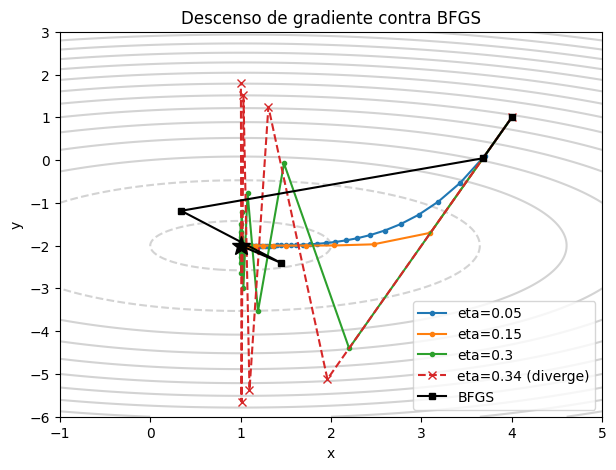

In [6]:
import matplotlib.pyplot as plt

# Camino de BFGS: se guarda cada iterado con callback
bfgs_pts = [np.array([4.0, 1.0])]
minimize(f, x0=[4, 1], method="BFGS", jac=grad, callback=lambda xk: bfgs_pts.append(xk.copy()))
bfgs_pts = np.array(bfgs_pts)

X, Y = np.meshgrid(np.linspace(-1, 5, 200), np.linspace(-6, 3, 200))
plt.figure(figsize=(7, 5))
plt.contour(X, Y, f([X, Y]), levels=15, colors="lightgray")     # curvas de nivel (tazón visto desde arriba)

for eta, c in [(0.05, "tab:blue"), (0.15, "tab:orange"), (0.30, "tab:green")]:
    cam = descenso(eta)[2]
    plt.plot(cam[:, 0], cam[:, 1], "o-", ms=3, color=c, label=f"eta={eta}")

cam_div = descenso(0.34, max_iter=6)[2]                          # primeros pasos de eta=0.34: se aleja
plt.plot(cam_div[:, 0], cam_div[:, 1], "x--", color="tab:red", label="eta=0.34 (diverge)")
plt.plot(bfgs_pts[:, 0], bfgs_pts[:, 1], "s-", ms=5, color="black", label="BFGS")

plt.plot(1, -2, "k*", ms=14)                                     # el mínimo (1, -2)
plt.xlim(-1, 5); plt.ylim(-6, 3)
plt.xlabel("x"); plt.ylabel("y"); plt.title("Descenso de gradiente contra BFGS")
plt.legend(); plt.show()

**Qué se ve en el gráfico:** con $\eta=0.05$ el camino es largo y suave; con $0.15$ llega en pocos pasos; con $0.30$ **zigzaguea** en la dirección $y$ antes de asentarse; con $0.34$ los saltos van de un lado al otro sin acercarse (y cada vez más lejos); y BFGS llega en 5 pasos aunque su camino no es una recta: los primeros pasos sirven para estimar la curvatura y los últimos ya apuntan al fondo. Las curvas de nivel son ovaladas (el eje $y$ es más empinado), que es lo que provoca el zigzag de los pasos grandes.

---
## Parte 3: Despacho de un mes lluvioso

En clase se despachó marzo de 2026 (época seca). Ahora toca **octubre de 2025**, un mes lluvioso: según Ember la demanda fue de **1070 GWh** y la generación hidroeléctrica de **910 GWh**. Se usan los mismos costos supuestos de la clase (miles de USD por GWh) y disponibilidades plausibles para ese mes.

El problema es de programación lineal:

$$\min\; c^\top x\quad\text{s.a.}\quad \sum_i x_i=\text{demanda},\qquad 0\le x_i\le \text{cap}_i$$

donde $x_i$ son los GWh que aporta cada fuente y $c_i$ su costo por GWh.

### 3.1 y 3.2 Octubre de 2025 y El Niño

In [7]:
from scipy.optimize import linprog
import pandas as pd

fuentes = ["hidro", "geotermia", "eolica", "biomasa", "importacion", "termica"]
costo = [15, 40, 60, 90, 120, 220]            # miles de USD por GWh (supuestos de la clase)

def despacho(cap, demanda):
    # Equality: la suma de las fuentes debe cubrir la demanda; cada fuente va de 0 a su capacidad
    r = linprog(costo, A_eq=[[1]*6], b_eq=[demanda],
                bounds=[(0, k) for k in cap], method="highs")
    print(dict(zip(fuentes, r.x.round(1).tolist())))
    print("costo:", r.fun, "| ultimo GWh cuesta:", r.eqlin.marginals[0])
    return r

oct25 = despacho([910, 130,  80, 10, 60, 500], 1070)    # octubre de 2025 (mes lluvioso)
nino  = despacho([750, 130,  80, 10, 60, 500], 1070)    # El Niño: solo 750 GWh de agua
# octubre: hidro 910, geotermia 130, eolica 30, resto 0
#          costo: 20650.0 | ultimo GWh cuesta: 60.0
# El Nino: hidro 750, geotermia 130, eolica 80, biomasa 10,
#          importacion 60, termica 40
#          costo: 38150.0 | ultimo GWh cuesta: 220.0

{'hidro': 910.0, 'geotermia': 130.0, 'eolica': 30.0, 'biomasa': 0.0, 'importacion': 0.0, 'termica': 0.0}
costo: 20650.0 | ultimo GWh cuesta: 60.0
{'hidro': 750.0, 'geotermia': 130.0, 'eolica': 80.0, 'biomasa': 10.0, 'importacion': 60.0, 'termica': 40.0}
costo: 38150.0 | ultimo GWh cuesta: 220.0


In [8]:
# Marzo de 2026 (la clase) con el mismo código, para comparar
marzo = despacho([660, 130, 200, 10, 60, 500], 1160)
# hidro 660, geotermia 130, eolica 200, biomasa 10, importacion 60, termica 100
# costo: 57200.0 | ultimo GWh cuesta: 220.0

{'hidro': 660.0, 'geotermia': 130.0, 'eolica': 200.0, 'biomasa': 10.0, 'importacion': 60.0, 'termica': 100.0}
costo: 57200.0 | ultimo GWh cuesta: 220.0


**Respuestas:**

1. **Octubre de 2025.** Hidro 910 + geotermia 130 + eólica 30 = 1070 GWh. **No se necesita térmica** (0 GWh): el agua alcanza y el costo mínimo es **20 650** miles de USD (unos 20,65 millones), contra 57 200 en marzo.
2. **Costo del último GWh** (`res.eqlin.marginals`): **60** miles de USD en octubre, contra **220** en marzo. Ese número es el costo de la fuente que "cierra" el balance, la que no está en su tope: en octubre es la eólica (usa 30 de 80 GWh) y en marzo es la térmica (usa 100 de 500 GWh). Un GWh más de demanda se cubre subiendo esa fuente una unidad.
3. **Escenario El Niño** (750 GWh de agua): hidro 750, geotermia 130, eólica 80, biomasa 10 e importación 60, todas en su tope, y **térmica 40 GWh** para cerrar el balance. El costo sube a **38 150**, es decir **17 500 miles de USD más** (+85 %), y el último GWh cuesta 220 como en marzo.

Dónde se va el aumento: los 160 GWh de agua que faltan se reponen con 50 GWh más de eólica, 10 de biomasa, 60 de importación y 40 de térmica:

$$\Delta C=-160(15)+50(60)+10(90)+60(120)+40(220)=-2400+3000+900+7200+8800=17\,500$$

### 3.3 Precios sombra de cada tope

`res.upper.marginals` da cuánto cambia el costo si se afloja en una unidad el tope de cada fuente (negativo: más capacidad, menos costo).

In [9]:
def tabla_cercas(r, cap, nombre):
    return pd.DataFrame({
        "fuente": fuentes,
        "usado": r.x.round(1),
        "tope": cap,
        "en_tope": np.isclose(r.x, cap),
        "valor_de_+1_GWh": (-r.upper.marginals).round(1) + 0.0,   # ahorro por cada GWh extra de tope (+0.0 evita el -0.0)
    }).set_index("fuente").add_prefix(nombre + ": ")

cap_oct  = [910, 130, 80, 10, 60, 500]
cap_nino = [750, 130, 80, 10, 60, 500]
print(tabla_cercas(oct25, cap_oct,  "oct ").to_string())
print()
print(tabla_cercas(nino,  cap_nino, "niño").to_string())
#              oct : usado  oct : tope  oct : en_tope  oct : valor_de_+1_GWh
# fuente
# hidro              910.0         910           True                  45.0
# geotermia          130.0         130           True                  20.0
# eolica              30.0          80          False                   0.0
# biomasa              0.0          10          False                   0.0
# importacion          0.0          60          False                   0.0
# termica              0.0         500          False                   0.0
#
#              niño: usado  niño: tope  niño: en_tope  niño: valor_de_+1_GWh
# hidro              750.0         750           True                 205.0
# geotermia          130.0         130           True                 180.0
# eolica              80.0          80           True                 160.0
# biomasa             10.0          10           True                 130.0
# importacion         60.0          60           True                 100.0
# termica             40.0         500          False                   0.0

             oct : usado  oct : tope  oct : en_tope  oct : valor_de_+1_GWh
fuente                                                                    
hidro              910.0         910           True                   45.0
geotermia          130.0         130           True                   20.0
eolica              30.0          80          False                    0.0
biomasa              0.0          10          False                    0.0
importacion          0.0          60          False                    0.0
termica              0.0         500          False                    0.0

             niño: usado  niño: tope  niño: en_tope  niño: valor_de_+1_GWh
fuente                                                                    
hidro              750.0         750           True                  205.0
geotermia          130.0         130           True                  180.0
eolica              80.0          80           True                  160.0
biomasa             10.0

**Lectura:** el valor de un GWh extra de tope es la diferencia entre el costo marginal del mes y el costo de esa fuente. En El Niño es $220-15=205$ para la hidro, $220-40=180$ para la geotermia, y así sucesivamente. En octubre es $60-15=45$ para la hidro y $60-40=20$ para la geotermia, porque la fuente marginal es la eólica (60). Las fuentes que no están en su tope valen 0 (sobra capacidad).

**¿Por qué salta el costo marginal de 60 a 220?** Mientras las fuentes baratas alcanzan, el último GWh lo aporta una fuente barata y poco usada (eólica, 60). Cuando se agotan todas, el último GWh solo puede venir de la térmica (220), por lo que el costo marginal da un **salto** en el momento en que se cambia de fuente marginal. Es la misma lógica de un escalón: el costo total crece, pero lo que más duele es que la última unidad se vuelve mucho más cara.

### 3.4 (Opcional) El mismo problema en `cvxpy`

In [10]:
import cvxpy as cp

def despacho_cvx(cap, demanda):
    x = cp.Variable(6)                                       # GWh de cada fuente
    balance = cp.sum(x) == demanda                           # hay que cubrir la demanda
    prob = cp.Problem(cp.Minimize(np.array(costo) @ x),
                      [balance, x >= 0, x <= np.array(cap)])
    prob.solve()
    return prob, x, balance

for nombre, cap in [("oct", cap_oct), ("nino", cap_nino)]:
    prob, x, balance = despacho_cvx(cap, 1070)
    print(nombre, np.abs(x.value).round(1).tolist(), "costo:", round(prob.value, 1),
          "| dual_value:", round(float(balance.dual_value), 1),
          "| costo del ultimo GWh (-dual_value):", round(-float(balance.dual_value), 1))
# oct [910.0, 130.0, 30.0, 0.0, 0.0, 0.0] costo: 20650.0 | dual_value: -60.0 | costo del ultimo GWh (-dual_value): 60.0
# nino [750.0, 130.0, 80.0, 10.0, 60.0, 40.0] costo: 38150.0 | dual_value: -220.0 | costo del ultimo GWh (-dual_value): 220.0

oct [910.0, 130.0, 30.0, 0.0, 0.0, 0.0] costo: 20650.0 | dual_value: -60.0 | costo del ultimo GWh (-dual_value): 60.0
nino [750.0, 130.0, 80.0, 10.0, 60.0, 40.0] costo: 38150.0 | dual_value: -220.0 | costo del ultimo GWh (-dual_value): 220.0


Es la misma solución y el mismo costo que con `linprog`: cambia la forma de escribirlo (`cvxpy` se parece a la matemática) y dónde se lee el precio sombra. **Ojo con el signo:** `balance.dual_value` sale como $-60$ y $-220$, es decir, con el signo opuesto a `res.eqlin.marginals` (que da $+60$ y $+220$) por la convención de cada librería. El costo del último GWh es `-balance.dual_value`. Conviene siempre verificar el signo con un caso conocido antes de interpretar un precio sombra.

---
## Parte 4: La decisión

### ¿Cuánto vale aflojar una cerca? Comprobación del precio sombra

El precio sombra es válido para cambios pequeños. Para ver hasta dónde, se afloja el tope de la hidro en El Niño:

In [11]:
# Se sube el tope de hidro de 750 a 790 y a 830 GWh y se compara el costo con el original (38150)
base = nino.fun
for extra in [0, 20, 40, 80]:
    r = linprog(costo, A_eq=[[1]*6], b_eq=[1070],
                bounds=[(0, k) for k in [750 + extra, 130, 80, 10, 60, 500]], method="highs")
    ahorro = base - r.fun
    por_gwh = ahorro / extra if extra else float("nan")
    print(f"+{extra:>2} GWh de agua: costo {r.fun:>8.0f}  ahorro {ahorro:>6.0f}  ({por_gwh:.0f} por GWh)  térmica {r.x[5]:.0f}")
# + 0 GWh de agua: costo    38150  ahorro      0  (nan por GWh)  térmica 40
# +20 GWh de agua: costo    34050  ahorro   4100  (205 por GWh)  térmica 20
# +40 GWh de agua: costo    29950  ahorro   8200  (205 por GWh)  térmica 0
# +80 GWh de agua: costo    25750  ahorro  12400  (155 por GWh)  térmica 0

+ 0 GWh de agua: costo    38150  ahorro      0  (nan por GWh)  térmica 40
+20 GWh de agua: costo    34050  ahorro   4100  (205 por GWh)  térmica 20
+40 GWh de agua: costo    29950  ahorro   8200  (205 por GWh)  térmica 0
+80 GWh de agua: costo    25750  ahorro  12400  (155 por GWh)  térmica 0


Cada GWh de agua extra ahorra 205 mientras la térmica sea la que cierra el balance, es decir, hasta los **40 GWh** que hoy se generan con térmica. Después de eso la hidro desplaza a la importación (120), así que el ahorro por GWh baja a $120-15=105$ y el promedio de los 80 GWh cae a 155. El precio sombra solo vale mientras no cambie cuál es la fuente marginal.

---

### Respuestas

**1. La cerca que aprieta.**

En el escenario de El Niño están **en su tope** cinco restricciones: hidro (750 GWh), geotermia (130), eólica (80), biomasa (10) e importación (60). La térmica (40 de 500 GWh) **no** está en su tope: tiene holgura y es la que cierra el balance de 1070 GWh, que también es una restricción activa (su precio sombra es 220).

| Tope | Valor de aflojarlo (miles de USD por GWh extra) |
|---|---|
| Hidro | **205** |
| Geotermia | 180 |
| Eólica | 160 |
| Biomasa | 130 |
| Importación | 100 |

Por unidad, lo que más **convendría aflojar es la hidro** (205): cada GWh de agua que se logre guardar o recuperar evita un GWh de térmica y ahorra $220-15=205$ mil USD, y es válido hasta 40 GWh. En la práctica la hidro depende de la lluvia y no se puede "aflojar" a voluntad, por lo que las palancas controlables serían **ampliar la importación o el aporte de geotermia y eólica**, que valen 100, 180 y 160 por GWh. Como solo hay 40 GWh de térmica por desplazar, cualquiera de ellas llega a ese tope de 40 GWh.

**2. El tamaño de paso.**

Bajar una montaña con los ojos cerrados, a pasos de un largo fijo: si los pasos son muy cortos se llega, pero tardando mucho (con $\eta=0.05$ hicieron falta 149 pasos). Si se dan pasos más largos se llega antes (con $0.15$, 44 pasos), pero **hay un largo a partir del cual uno se pasa del fondo**: se cae al otro lado de la hondonada, el siguiente paso devuelve y la trayectoria rebota de un lado al otro. Con $\eta=0.30$ ya rebotaba en una de las direcciones y por eso necesitó 75 pasos, más que con $0.15$. Con $0.34$ cada rebote era más grande que el anterior y el método **se disparó** en lugar de llegar. El límite lo marca la dirección con más curvatura (la más empinada): se necesita $\eta<2/6\approx0.33$. Así que "más grande" no es "más rápido": el paso ideal es el más grande que no rebota, y encontrarlo exige conocer la forma del terreno, que es justo lo que métodos como BFGS estiman por su cuenta (5 pasos en este problema).

**3. El proyecto.**

El avance 1 pronostica las órdenes mensuales de LightForce Orthodontics con un SARIMA$(1,1,0)(0,1,0)_{12}$ estimado por máxima verosimilitud. Por debajo, ese ajuste es una minimización:

$$\text{minimizar}\;\; -\ell(\phi_1,\sigma^2)\;\;\text{(equivalente a minimizar la suma de errores cuadráticos de un paso)}\quad\text{sujeto a}\quad \lvert\phi_1\rvert<1$$

donde $\ell$ es la log-verosimilitud, $\phi_1$ el coeficiente AR(1) de la serie diferenciada y $\sigma^2$ la varianza del error. La restricción es la **estacionariedad** del término AR (en un SARIMA con más términos también se imponen invertibilidad en los MA y raíces fuera del círculo unitario). Es una cerca "suave": los programas de ajuste la imponen al buscar los parámetros.

Para el segundo método de la entrega final (Chronos-2, sin entrenamiento) no hay un ajuste de este tipo, pero el pronóstico alimenta una decisión que sí es un problema de optimización, igual que el despacho de esta práctica. Una **propuesta para el proyecto**, que habría que validar con los supervisores de manufactura:

$$\text{minimizar}\;\; \text{costo de turnos y horas extra}\quad\text{sujeto a}\quad \text{capacidad del mes}\ge\text{pronóstico (p. ej. percentil 80)},\;\; \text{horas por técnico}\le\text{límite}$$

Es programación lineal como `linprog`, y el precio sombra de la restricción de capacidad diría cuánto cuesta cubrir una orden adicional.

---

**Para la clase 10:** los precios sombra de esta práctica (205, 180, 160, 130, 100 y 220) son el punto de partida. Se explican con los **multiplicadores de Lagrange** y las **condiciones KKT**: cada cerca "aprieta" (está en su tope y tiene precio sombra mayor que 0) o "sobra" (tiene holgura y precio sombra 0), como se vio en la tabla de la parte 3.